# Tidy Up Your Data: Online Retail II

Dataset: `online_retail_II.csv` (1,067,371 rows × 8 columns).

Workflow: **1 Profiling -> 2 Structuring -> 3 Cleansing -> 4 Outlier flagging -> 5 Enrichment**

- `dt_raw` is an untouched copy of the raw data, used for profiling and before/after comparisons.
- Rules that **remove** rows are listed in section 3. Suspicious values (outliers) are **flagged, not deleted**.

In [1]:
import os
import numpy as np
import pandas as pd
from scipy import stats
from fuzzywuzzy import fuzz
from IPython.display import display
import matplotlib.pyplot as plt

dt = pd.read_csv("Dataset/online_retail_II.csv")
dt_raw = dt.copy() # untouched copy

## 1. Profiling (raw data)

Syntactic, semantic and set-based profiling.

In [2]:
# Shape of the Dataset. i.e. rows, columns
dt_raw.shape

(1067371, 8)

In [3]:
dt_raw.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [4]:
dt_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   Invoice      1067371 non-null  str    
 1   StockCode    1067371 non-null  str    
 2   Description  1062989 non-null  str    
 3   Quantity     1067371 non-null  int64  
 4   InvoiceDate  1067371 non-null  str    
 5   Price        1067371 non-null  float64
 6   Customer ID  824364 non-null   float64
 7   Country      1067371 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 136.6 MB


In [5]:
dt_raw.isna().sum()

Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64

In [6]:
dt_raw.nunique()

Invoice        53628
StockCode       5305
Description     5698
Quantity        1057
InvoiceDate    47635
Price           2807
Customer ID     5942
Country           43
dtype: int64

In [7]:
# Sum of Unique Values by Column
for i in dt_raw.columns:
    print(f'{dt_raw[i].value_counts()}\n\n')

Invoice
537434     1350
538071     1304
537638     1202
537237     1194
536876     1186
           ... 
581487        1
581491        1
C581499       1
581566        1
C581568       1
Name: count, Length: 53628, dtype: int64


StockCode
85123A    5829
22423     4424
85099B    4216
21212     3318
20725     3259
          ... 
85049c       1
84971l       1
85034b       1
23609        1
23617        1
Name: count, Length: 5305, dtype: int64


Description
WHITE HANGING HEART T-LIGHT HOLDER    5918
REGENCY CAKESTAND 3 TIER              4412
JUMBO BAG RED RETROSPOT               3469
ASSORTED COLOUR BIRD ORNAMENT         2958
PARTY BUNTING                         2765
                                      ... 
wet?                                     1
lost??                                   1
???                                      1
wet boxes                                1
????damages????                          1
Name: count, Length: 5698, dtype: int64


Quantity
 1        294346
 2 

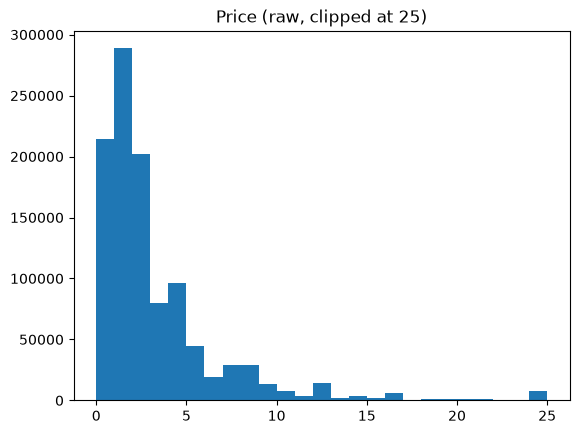

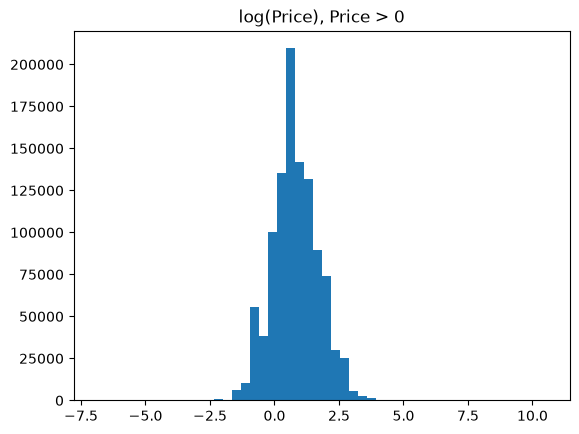

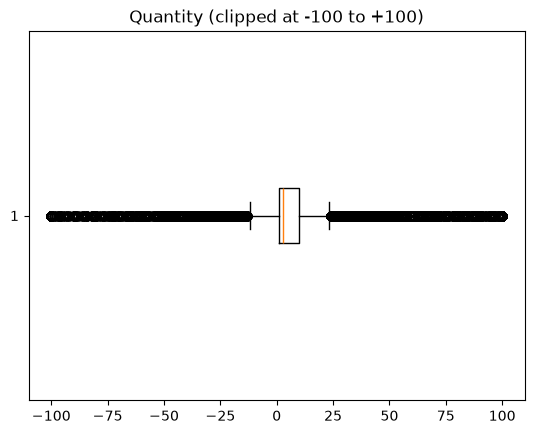

In [8]:
fig, ax = plt.subplots()
ax.hist(dt_raw["Price"].clip(0, 25), bins=25)
ax.set_title("Price (raw, clipped at 25)")
fig.savefig("Figures/price_raw.png", dpi=300, bbox_inches="tight")
plt.show()
fig, ax = plt.subplots()
ax.hist(np.log(dt_raw.loc[dt_raw["Price"] > 0, "Price"]), bins=50)
ax.set_title("log(Price), Price > 0")
fig.savefig("Figures/log_price.png", dpi=300, bbox_inches="tight")
plt.show()
fig, ax = plt.subplots()
ax.boxplot(dt_raw["Quantity"].clip(-100, 100), orientation='horizontal')
ax.set_title("Quantity (clipped at -100 to +100)")
fig.savefig("Figures/Quantity.png", dpi=300, bbox_inches="tight")
plt.show()

### Syntactic profiling

In [9]:
# character patterns (digits -> 9, letters -> A)
def pattern(s):
    return s.str.replace(r"\d", "9", regex=True).str.replace(r"[A-Za-z]", "A", regex=True)

In [10]:
pattern(dt_raw["StockCode"]).value_counts()

StockCode
99999           932385
99999A          127520
AAAA              2158
A                 1713
AAA               1446
99999AA           1372
A9                 283
AAAA9999           103
AAAA AAAAAAA       102
AAAA_9999_99       100
AAAAAAAAA           69
AAAAAA              67
AAAAAAAA            24
AAAA999             17
AAAA9999A            5
AAAAAA9              3
AA9999               3
99999A               1
Name: count, dtype: int64

In [11]:
pattern(dt_raw["Invoice"]).value_counts()

Invoice
999999     1047871
A999999      19500
Name: count, dtype: int64

### Set-based and semantic profiling

In [12]:
display(
    dt_raw[["Quantity", "Price", "Customer ID"]].describe().style.format(
        lambda v: f"{int(v):,}" if v.is_integer() else f"{v:,.2f}"
    )
)

,Quantity,Price,Customer ID
count,"1,067,371","1,067,371","824,364"
mean,9.94,4.65,"15,324.64"
std,172.71,123.55,"1,697.46"
min,"-80,995","-53,594.36","12,346"
25%,1,1.25,"13,975"
50%,3,2.10,"15,255"
75%,10,4.15,"16,797"
max,"80,995","38,970","18,287"


In [13]:
print("Quantity < 0:", (dt_raw["Quantity"] < 0).sum(), "| Quantity == 0:", (dt_raw["Quantity"] == 0).sum())

Quantity < 0: 22950 | Quantity == 0: 0


In [14]:
print("Price < 0:", (dt_raw["Price"] < 0).sum(), "| Price == 0:", (dt_raw["Price"] == 0).sum())

Price < 0: 5 | Price == 0: 6202


In [15]:
# Cancellation prefix "C" vs negative Price
is_c = dt_raw["Invoice"].str.startswith("C")
pd.crosstab(is_c, dt_raw["Price"] <= 0)

Price,False,True
Invoice,,
False,1041670,6207
True,19494,0


In [16]:
# Cancellation prefix "C" vs negative Quantity
is_c = dt_raw["Invoice"].str.startswith("C")
pd.crosstab(is_c, dt_raw["Quantity"] < 0)

Quantity,False,True
Invoice,,
False,1044420,3457
True,1,19493


In [17]:
dt_raw[is_c & (dt_raw["Quantity"] > 0)] # the one C row with non-negative Quantity

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
76799,C496350,M,Manual,1,2010-02-01 08:24:00,373.57,NaN,United Kingdom


In [18]:
# Cancellation prefix "A" vs negative Price
is_a = dt_raw["Invoice"].str.startswith("A")
display(pd.crosstab(is_a, dt_raw["Price"] < 0))
display(pd.crosstab(is_a, dt_raw["Price"] == 0))

Price,False,True
Invoice,,
False,1067365,0
True,1,5


Price,False,True
Invoice,,
False,1061163,6202
True,6,0


In [19]:
# Cancellation prefix "a" vs negative Quantity
is_a = dt_raw["Invoice"].str.startswith("A")
pd.crosstab(is_a, dt_raw["Quantity"] < 0)

Quantity,False,True
Invoice,,
False,1044415,22950
True,6,0


In [20]:
dt_raw[is_a & (dt_raw["Price"] > 0)] # the one A row with non-negative Quantity

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
825443,A563185,B,Adjust bad debt,1,2011-08-12 14:50:00,11062.06,NaN,United Kingdom


In [21]:
dt_raw.loc[dt_raw["Invoice"].str.match(r"^[A-Za-z]"), "Invoice"].str[0].value_counts()

Invoice
C    19494
A        6
Name: count, dtype: int64

In [22]:
# Non-"C" negative quantities: share of missing values
neg_noc = dt_raw[(~is_c) & (dt_raw["Quantity"] < 0)]
print(f'Missing description in non-C invoices and negative quantities: {neg_noc["Description"].isna().mean():.0%}'
      f'\nZero price in non-C invoices and negative quantities: {(neg_noc["Price"] == 0).mean():.0%}'
      f'\nMissing Customer ID in non-C invoices and negative quantities: {neg_noc["Customer ID"].isna().mean():.0%}')

Missing description in non-C invoices and negative quantities: 78%
Zero price in non-C invoices and negative quantities: 100%
Missing Customer ID in non-C invoices and negative quantities: 100%


In [23]:
# Zero price rows: share of missing values
zero_price = dt_raw[dt_raw["Price"] == 0]
print(zero_price[["Description", "Customer ID"]].isna().mean().to_string(float_format='{:.2%}'.format))

Description   70.65%
Customer ID   98.86%


In [24]:
# Duplicates, StockCode case, extreme values
show_cols = ["Invoice", "StockCode", "Description", "Quantity", "Price", "Customer ID", "InvoiceDate"]

print("Duplicated rows:", dt_raw.duplicated().sum())
print("StockCodes with lowercase letters:", dt_raw.loc[dt_raw["StockCode"].str.contains(r"[a-z]"), "StockCode"].nunique())
print("StockCode distinct (raw vs upper):", dt_raw["StockCode"].nunique(), "vs", dt_raw["StockCode"].str.upper().nunique())

display(dt_raw[dt_raw["Price"] < 0][show_cols]) # Negative price
display(dt_raw.nlargest(10, "Price")[show_cols]) # Extreme price
display(dt_raw.nlargest(10, "Quantity")[show_cols]) # Extreme quantity

# Non-standard StockCodes
std_code = dt_raw["StockCode"].str.match(r"^\d{5}[A-Za-z]{0,2}$")
display(dt_raw.loc[~std_code, ["StockCode", "Description"]].drop_duplicates("StockCode").head(40))

Duplicated rows: 34335
StockCodes with lowercase letters: 183
StockCode distinct (raw vs upper): 5305 vs 5132


,Invoice,StockCode,Description,Quantity,Price,Customer ID,InvoiceDate
179403,A506401,B,Adjust bad debt,1,-53594.36,NaN,2010-04-29 13:36:00
276274,A516228,B,Adjust bad debt,1,-44031.79,NaN,2010-07-19 11:24:00
403472,A528059,B,Adjust bad debt,1,-38925.87,NaN,2010-10-20 12:04:00
825444,A563186,B,Adjust bad debt,1,-11062.06,NaN,2011-08-12 14:51:00
825445,A563187,B,Adjust bad debt,1,-11062.06,NaN,2011-08-12 14:52:00


,Invoice,StockCode,Description,Quantity,Price,Customer ID,InvoiceDate
748142,C556445,M,Manual,-1,38970.00,15098.0,2011-06-10 15:31:00
241824,C512770,M,Manual,-1,25111.09,17399.0,2010-06-17 16:52:00
241827,512771,M,Manual,1,25111.09,NaN,2010-06-17 16:53:00
320581,C520667,BANK CHARGES,Bank Charges,-1,18910.69,NaN,2010-08-27 13:42:00
1050063,C580605,AMAZONFEE,AMAZON FEE,-1,17836.46,NaN,2011-12-05 11:36:00
569163,C540117,AMAZONFEE,AMAZON FEE,-1,16888.02,NaN,2011-01-05 09:55:00
569164,C540118,AMAZONFEE,AMAZON FEE,-1,16453.71,NaN,2011-01-05 09:57:00
517953,C537630,AMAZONFEE,AMAZON FEE,-1,13541.33,NaN,2010-12-07 15:04:00
517955,537632,AMAZONFEE,AMAZON FEE,1,13541.33,NaN,2010-12-07 15:08:00
519294,C537651,AMAZONFEE,AMAZON FEE,-1,13541.33,NaN,2010-12-07 15:49:00


,Invoice,StockCode,Description,Quantity,Price,Customer ID,InvoiceDate
1065882,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,16446.0,2011-12-09 09:15:00
587080,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,12346.0,2011-01-18 10:01:00
90857,497946,37410,BLACK AND WHITE PAISLEY FLOWER MUG,19152,0.10,13902.0,2010-02-15 11:57:00
127166,501534,21099,SET/6 STRAWBERRY PAPER CUPS,12960,0.10,13902.0,2010-03-17 13:09:00
127168,501534,21091,SET/6 WOODLAND PAPER PLATES,12960,0.10,13902.0,2010-03-17 13:09:00
127169,501534,21085,SET/6 WOODLAND PAPER CUPS,12744,0.10,13902.0,2010-03-17 13:09:00
1027583,578841,84826,ASSTD DESIGN 3D PAPER STICKERS,12540,0.00,13256.0,2011-11-25 15:57:00
127167,501534,21092,SET/6 STRAWBERRY PAPER PLATES,12480,0.10,13902.0,2010-03-17 13:09:00
192197,507637,84016,FLAG OF ST GEORGE CAR FLAG,10200,0.00,NaN,2010-05-10 14:55:00
135027,502269,21984,PACK OF 12 PINK PAISLEY TISSUES,10000,0.25,17940.0,2010-03-23 15:36:00


,StockCode,Description
89,POST,POSTAGE
735,D,Discount
2377,DCGS0058,MISO PRETTY GUM
2378,DCGS0068,DOGS NIGHT COLLAR
2379,DOT,DOTCOM POSTAGE
2697,M,Manual
8371,DCGS0004,HAYNES CAMPER SHOULDER BAG
8373,DCGS0076,SUNJAR LED NIGHT NIGHT LIGHT
9292,C2,CARRIAGE
18410,BANK CHARGES,Bank Charges


### Issues found

| Issue | Evidence | Dimension |
|---|---|---|
| Missing `Customer ID` | 243,007 rows (22.77 %) | Completeness |
| Missing `Description` | 4,382 rows (0.41 %) | Completeness |
| Wrong types | `Customer ID` float, `InvoiceDate` string | Representational (syntax) |
| Exact duplicates | 34,335 rows (3.22 %) | Uniqueness |
| `C` invoices / negative `Quantity` | 19,494 / 22,950 rows | Interpretability |
| Zero / negative `Price` | 6,202 / 5 rows | Accuracy |
| Non-product `StockCode`s | e.g. `POST`, `DOT`, `M`, `B`, `AMAZONFEE`, gift vouchers | Relevancy |
| `StockCode` case | 5,305 -> 5,132 distinct after `upper()` | Representational consistency |
| `Country` values | `Unspecified` (756), mixed naming | Accuracy, consistency |
| Extreme `Quantity` / `Price` | max 80,995 / 38,970 | Accuracy |

## 2. Structuring

Fix types, standardize text, add flags. No rows are removed here.

- **`Country`:** `EIRE`, `RSA` and `USA` were renamed. `Unspecified` (756) is not a country and was set to missing, not removed. `Korea` (63 rows) was left unchanged because the data doesn't say which Korea. `Channel Islands` and `West Indies` are regions, not single countries, and were also left unchanged.

In [25]:
# Types
dt["InvoiceDate"] = pd.to_datetime(dt["InvoiceDate"])
dt["Customer ID"] = dt["Customer ID"].astype("Int64")

# Standardize text
dt["StockCode"] = dt["StockCode"].str.strip().str.upper()
dt["Description"] = dt["Description"].str.strip().str.replace(r"\s+", " ", regex=True)

# Flags
non_product = ["POST", "DOT", "D", "M", "C2", "BANK CHARGES", "ADJUST", "ADJUST2",
               "TEST001", "TEST002", "AMAZONFEE", "B", "GIFT", "S", "CRUK"]
dt["is_cancellation"] = dt["Invoice"].str.startswith("C")
dt["is_non_product"] = dt["StockCode"].isin(non_product) | dt["StockCode"].str.startswith("GIFT_")

In [26]:
# Checks
dt.info()

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 10 columns):
 #   Column           Non-Null Count    Dtype         
---  ------           --------------    -----         
 0   Invoice          1067371 non-null  str           
 1   StockCode        1067371 non-null  str           
 2   Description      1062989 non-null  str           
 3   Quantity         1067371 non-null  int64         
 4   InvoiceDate      1067371 non-null  datetime64[us]
 5   Price            1067371 non-null  float64       
 6   Customer ID      824364 non-null   Int64         
 7   Country          1067371 non-null  str           
 8   is_cancellation  1067371 non-null  bool          
 9   is_non_product   1067371 non-null  bool          
dtypes: Int64(1), bool(2), datetime64[us](1), float64(1), int64(1), str(4)
memory usage: 120.2 MB


In [27]:
print("StockCode distinct:", dt_raw["StockCode"].nunique(), "->", dt["StockCode"].nunique())
print("Description distinct:", dt_raw["Description"].nunique(), "->", dt["Description"].nunique())
print("Cancellations:", dt["is_cancellation"].sum(), "| Non-product rows:", dt["is_non_product"].sum())

StockCode distinct: 5305 -> 5131
Description distinct: 5698 -> 5644
Cancellations: 19494 | Non-product rows: 5912


In [28]:
# Country: standardize naming, treat non-country values as missing
country_map = {"EIRE": "Ireland", "RSA": "South Africa", "USA": "United States"}
dt["Country"] = dt["Country"].str.strip().replace(country_map)
dt["Country"] = dt["Country"].mask(dt["Country"].eq("Unspecified"))

In [29]:
print("Country missing:", dt["Country"].isna().sum())

Country missing: 756


In [30]:
dt.loc[dt["is_non_product"], "StockCode"].value_counts()

StockCode
POST            2122
DOT             1446
M               1426
C2               282
D                177
S                104
BANK CHARGES     102
ADJUST            67
AMAZONFEE         43
GIFT_0001_20      29
GIFT_0001_30      29
GIFT_0001_10      16
CRUK              16
TEST001           15
GIFT_0001_50       8
GIFT_0001_40       7
B                  6
GIFT_0001_80       4
GIFT_0001_70       3
ADJUST2            3
TEST002            2
GIFT_0001_60       2
GIFT_0001_90       2
GIFT               1
Name: count, dtype: int64

In [31]:
# Non-standard codes not covered by the flag
rest = ~dt["StockCode"].str.match(r"^\d{5}[A-Z]{0,2}$") & ~dt["is_non_product"]
dt.loc[rest, ["StockCode", "Description", "Quantity", "Price"]].drop_duplicates("StockCode")

,StockCode,Description,Quantity,Price
2377,DCGS0058,MISO PRETTY GUM,1,0.830
2378,DCGS0068,DOGS NIGHT COLLAR,1,8.650
8371,DCGS0004,HAYNES CAMPER SHOULDER BAG,1,17.350
8373,DCGS0076,SUNJAR LED NIGHT NIGHT LIGHT,1,16.480
20249,DCGS0003,BOXED GLASS ASHTRAY,1,2.570
30672,DCGS0072,CAT CAMOUFLAGUE COLLAR,1,5.170
33819,DCGS0044,HANDZ-OFF CAR FRESHENER,1,2.570
44245,DCGS0066N,NAVY CUDDLES DOG HOODIE,1,8.650
62299,PADS,PADS TO MATCH ALL CUSHIONS,1,0.001
80231,DCGSSGIRL,NaN,-1,0.000


## 3. Cleansing (rules that remove rows)

Five rules: exact duplicates, non-product codes, zero price, negative price, negative quantity outside `C` invoices.

**Fuzzy matching:** Variants of a `Description` within one `StockCode` are compared with the most frequent description of that code using `fuzz.ratio` (fuzzywuzzy, 0-100). Variants with a score >= 95 are replaced in `Description_std`.

In [32]:
raw_cols = list(dt_raw.columns)
dt["is_duplicate"] = dt.duplicated(subset=raw_cols)
dt["zero_price"] = dt["Price"] == 0
dt["neg_price"] = dt["Price"] < 0
dt["neg_qty_noncancel"] = (dt["Quantity"] < 0) & ~dt["is_cancellation"]

rules = ["is_duplicate", "is_non_product", "zero_price", "neg_price", "neg_qty_noncancel"]
hits = dt[rules].sum(axis=1)

display(dt[rules].sum().rename("rows per rule"))
print(f"\n{'Total rows:':<32} {len(dt):>10,}")
print(f"{'Rows left if all rules applied:':<32} {(hits == 0).sum():>10,} ({(hits == 0).sum() / len(dt):>5.1%})")
print(f"{'Rows hit by more than one rule:':<32} {(hits > 1).sum():>10,} ({(hits > 1).sum() / len(dt):>5.1%})")
print(f"\nShare of missing Description with Price equal to 0: {dt.loc[dt["Description"].isna(), "Price"].eq(0).mean():.0%}")

is_duplicate         34335
is_non_product        5912
zero_price            6202
neg_price                5
neg_qty_noncancel     3457
Name: rows per rule, dtype: int64


Total rows:                       1,067,371
Rows left if all rules applied:   1,021,272 (95.7%)
Rows hit by more than one rule:       3,747 ( 0.4%)

Share of missing Description with Price equal to 0: 100%


In [33]:
clean = dt[hits == 0].drop(columns=rules).copy()
keep_dups = dt[dt[rules[1:]].sum(axis=1) == 0] # all rules except duplicates

print("C invoices with non-negative Quantity in clean data:",
      (clean["is_cancellation"] & (clean["Quantity"] >= 0)).sum())
print("Missing Description in clean data:", clean["Description"].isna().sum())
print("Remaining negative Quantity (cancellations):", (clean["Quantity"] < 0).sum())

C invoices with non-negative Quantity in clean data: 0
Missing Description in clean data: 0
Remaining negative Quantity (cancellations): 17915


In [34]:
def summary(d):
    rev = d["Quantity"] * d["Price"]
    return pd.Series({
        "rows": len(d),
        "missing_customer": d["Customer ID"].isna().sum(),
        "missing_description": d["Description"].isna().sum(),
        "Quantity_mean": d["Quantity"].mean(), "Quantity_std": d["Quantity"].std(),
        "Price_mean": d["Price"].mean(), "Price_std": d["Price"].std(),
        "Price_min": d["Price"].min(), "Price_max": d["Price"].max(),
        "revenue_sum": rev.sum()})

comparison_df = pd.concat({
    "raw": summary(dt_raw),
    "clean": summary(clean),
    "clean_keep_dups": summary(keep_dups)
}, axis=1)

display(
    comparison_df.style.format(
        lambda v: f"{int(v):,}" if v.is_integer() else f"{v:,.2f}"
    )
)

,raw,clean,clean_keep_dups
rows,"1,067,371","1,021,272","1,055,307"
missing_customer,"243,007","227,089","234,722"
missing_description,"4,382",0,0
Quantity_mean,9.94,10.50,10.35
Quantity_std,172.71,169.08,166.69
Price_mean,4.65,3.36,3.36
Price_std,123.55,4.87,4.85
Price_min,"-53,594.36",0.00,0.00
Price_max,"38,970","1,157.15","1,157.15"
revenue_sum,"19,287,250.57","18,927,399.07","19,383,625.03"


**`C` invoice with positive `Quantity`:** `C496350` (`StockCode` `M` "Manual", `Quantity` 1, `Price` 373.57, no `Customer ID`). It is removed by the non-product rule. In the clean data, `C` invoices all have negative `Quantity` (checked in section 3).

In [35]:
# Revenue of the lines each rule flags; removing them changes net revenue by minus this
rev = dt["Quantity"] * dt["Price"]
print(f'{pd.DataFrame({r: {"lines": int(dt[r].sum()), "revenue": rev[dt[r]].sum()} for r in rules})
      .T.to_string(formatters={"lines": "{:.0f}".format, "revenue": "{:.2f}".format})}')

                  lines    revenue
is_duplicate      34335  431716.87
is_non_product     5912  -96374.46
zero_price         6202       0.00
neg_price             5 -158676.14
neg_qty_noncancel  3457       0.00


In [36]:
# Unique customers
dt_raw["Customer ID"].nunique()

5942

In [37]:
# Customers with no row left after cleansing
lost = set(dt["Customer ID"].dropna()) - set(clean["Customer ID"].dropna())
d_lost = dt[dt["Customer ID"].isin(lost)]

In [38]:
print(len(lost), "customers |", len(d_lost), "rows")

67 customers | 120 rows


In [39]:
print(d_lost[rules].sum())  # rows per rule (overlapping)

is_duplicate           0
is_non_product       119
zero_price             3
neg_price              0
neg_qty_noncancel      0
dtype: int64


In [40]:
print(d_lost.groupby("Customer ID")[rules].any().sum())  # customers with at least one row hit, per rule

is_duplicate          0
is_non_product       66
zero_price            3
neg_price             0
neg_qty_noncancel     0
dtype: int64


In [41]:
d_lost.groupby("Customer ID").size().describe().to_frame().style.format(
    lambda v: f"{int(v):,}" if v.is_integer() else f"{v:,.2f}"
)  # rows per lost customer

,0
count,67
mean,1.79
std,1.68
min,1
25%,1
50%,1
75%,2
max,8


In [42]:
d_lost.sort_values("Customer ID")[show_cols].head(20)

,Invoice,StockCode,Description,Quantity,Price,Customer ID,InvoiceDate
70987,C495743,ADJUST,Adjustment by john on 26/01/2010 16,-1,18.38,12382,2010-01-26 16:25:00
70985,495742,ADJUST,Adjustment by john on 26/01/2010 16,1,63.24,12404,2010-01-26 16:25:00
71022,495745,ADJUST,Adjustment by john on 26/01/2010 16,1,56.73,12466,2010-01-26 16:26:00
71033,495747,ADJUST,Adjustment by john on 26/01/2010 16,1,129.23,12555,2010-01-26 16:26:00
71081,495801,ADJUST,Adjustment by john on 26/01/2010 17,1,77.52,12570,2010-01-26 17:28:00
70980,495736,ADJUST,Adjustment by john on 26/01/2010 16,1,21.00,12606,2010-01-26 16:23:00
126,489444,POST,POSTAGE,1,141.00,12636,2009-12-01 09:55:00
70984,C495744,ADJUST,Adjustment by john on 26/01/2010 16,-1,91.89,12706,2010-01-26 16:25:00
288706,517483,M,Manual,1,3610.50,12737,2010-07-29 12:29:00
288685,517481,C2,CARRIAGE,1,100.00,12737,2010-07-29 12:27:00


**Lost customers:** 67 of 5,942 customers (1.13 %) have no row left after cleansing. They had 120 rows in total (mean 1.8, max 8 per customer). All of these rows were removed by the non-product rule (119 rows, 66 customers) or the zero-price rule (3 rows, 3 customers); 2 rows are hit by both. Customer-level analyses therefore exclude them.

In [43]:
# How many StockCodes have more than one Description in the clean data?
n_desc = clean.groupby("StockCode")["Description"].nunique()
print(clean["Description"].nunique(), "descriptions |", clean["StockCode"].nunique(), "StockCodes |",
      (n_desc > 1).sum(), "StockCodes with more than one description")

# Compare each variant with the most frequent description of its StockCode
ref = clean.groupby("StockCode")["Description"].agg(lambda s: s.value_counts().index[0])
variants = clean.groupby(["StockCode", "Description"]).size().rename("rows").reset_index()
variants["reference"] = variants["StockCode"].map(ref)
variants = variants[variants["Description"] != variants["reference"]].copy()
variants["score"] = [fuzz.ratio(a, b) for a, b in zip(variants["Description"], variants["reference"])]

for k in (80, 90, 95):
    print(f"score >= {k}:", (variants["score"] >= k).sum(), "variants")

5340 descriptions | 4739 StockCodes | 596 StockCodes with more than one description
score >= 80: 421 variants
score >= 90: 229 variants
score >= 95: 177 variants


In [44]:
display(variants.sort_values("score", ascending=False).head(15))
display(variants.sort_values("score").head(15))

,StockCode,Description,rows,reference,score
1788,22353,LUNCHBOX WITH CUTLERY FAIRY CAKES,202,LUNCH BOX WITH CUTLERY FAIRY CAKES,99
1750,22333,RETRO SPOT PARTY BAG + STICKER SET,35,RETROSPOT PARTY BAG + STICKER SET,99
1364,21955,DOOR MAT UNION JACK GUNS AND ROSES,230,DOORMAT UNION JACK GUNS AND ROSES,99
961,21523,DOOR MAT FANCY FONT HOME SWEET HOME,246,DOORMAT FANCY FONT HOME SWEET HOME,99
661,21210,SET OF 72 RETRO SPOT PAPER DOILIES,560,SET OF 72 RETROSPOT PAPER DOILIES,99
3154,23484,HEART TRELLISTRIPLE T-LIGHT HOLDER,5,HEART TRELLIS TRIPLE T-LIGHT HOLDER,99
979,21533,RETROSPOT LARGE MILK JUG,454,RETRO SPOT LARGE MILK JUG,98
964,21524,DOOR MAT SPOTTY HOME SWEET HOME,287,DOORMAT SPOTTY HOME SWEET HOME,98
2560,22972,CHILDRENS SPACEBOY MUG,5,CHILDREN'S SPACEBOY MUG,98
2511,22937,BAKING MOULD CHOCOLATE CUP CAKES,2,BAKING MOULD CHOCOLATE CUPCAKES,98


,StockCode,Description,rows,reference,score
2356,22829,BROCANTE SHELF WITH HOOKS,1,SWEETHEART WIRE WALL TIDY,28
2361,22832,SWEETHEART WIRE WALL TIDY,3,BROCANTE SHELF WITH HOOKS,28
1973,22510,DOORSTOP RUSSIAN DOLL GINGHAM,28,GINGHAM BABUSHKA DOORSTOP,30
1734,22323,BAG FOR CHILDREN VINTAGE PINK,1,PINK POLKADOT KIDS BAG,31
1736,22324,BAG FOR CHILDREN VINTAGE BLUE,1,BLUE POLKADOT KIDS BAG,35
2876,23236,DOILEY BISCUIT TIN,13,STORAGE TIN VINTAGE DOILY,37
1522,22139,11 PC CERAMIC TEA SET POLKADOT,1,RETROSPOT TEA SET CERAMIC 11 PC,39
1215,21786,RAIN HAT WITH RED SPOTS,160,POLKADOT RAIN HAT,40
246,20685,RED SPOTTY COIR DOORMAT,209,DOORMAT RED RETROSPOT,41
4651,84997A,CHILDRENS CUTLERY POLKADOT GREEN,249,GREEN 3 PIECE MINI DOTS CUTLERY SET,42


In [45]:
pairs = pd.MultiIndex.from_frame(clean[["StockCode", "Description"]])
lookup = variants.loc[variants["score"] >= 95].set_index(["StockCode", "Description"])["reference"]
clean["Description_std"] = lookup.reindex(pairs).set_axis(clean.index).fillna(clean["Description"])

print(clean["Description"].nunique(), "->", clean["Description_std"].nunique())

5340 -> 5163


**`Description` variants:** fuzzy matching cannot tell a typo from a legitimate rename or a different product under the same `StockCode`. The most frequent description is the reference (ties are arbitrary). The original `Description` is kept. The same description under different codes is not handled.

## 4. Outlier detection

- Z-score flags (thresholds 2 and 3) plus a product-level price ratio.
- **`PADS`:** 17 rows with `Price` 0.001 (15 customers, all with `Customer ID`) are kept and flagged as `tiny_price`. They are excluded from `Price_log`. Their `Revenue` rounds to 0.00 (0.017 in total). The single `PADS` row at 36.60 is flagged by `price_ratio_ge10`, that flag is an artifact of the 0.001 median.

In [46]:
clean["has_customer"] = clean["Customer ID"].notna()

for col in ["Quantity", "Price"]:
    z = np.abs(stats.zscore(clean[col]))
    clean[f"{col}_z2"] = z >= 2
    clean[f"{col}_z3"] = z >= 3

display(clean[["Quantity_z2", "Quantity_z3", "Price_z2", "Price_z3"]].sum())
display(clean[["Quantity", "Price"]].describe().style.format(
        lambda v: f"{int(v):,}" if v.is_integer() else f"{v:,.2f}"
    ))

Quantity_z2     1904
Quantity_z3      997
Price_z2       20455
Price_z3        7228
dtype: int64

,Quantity,Price
count,"1,021,272","1,021,272"
mean,10.50,3.36
std,169.08,4.87
min,"-80,995",0.00
25%,1,1.25
50%,3,2.10
75%,10,4.13
max,"80,995","1,157.15"


In [47]:
# Tiny prices
print("Price < 0.01:", (clean["Price"] < 0.01).sum())

Price < 0.01: 17


In [48]:
clean[clean["Price"] < 0.01][["StockCode", "Quantity", "Price"]].value_counts()

StockCode  Quantity  Price
PADS       1         0.001    17
Name: count, dtype: int64

In [49]:
pads = clean[clean["Price"] <= 0.001]
display(pads[["Invoice", "StockCode", "Description", "Quantity", "Price", "Customer ID", "InvoiceDate"]])
print(f'Unique customers: {pads["Customer ID"].nunique()}\nCustomers without Customer ID: {pads["Customer ID"].isna().mean():.0%}')
print(f'\n{dt.loc[dt["StockCode"] == "PADS", "Price"].value_counts()}') # all PADS rows, including removed ones

,Invoice,StockCode,Description,Quantity,Price,Customer ID,InvoiceDate
62299,494914,PADS,PADS TO MATCH ALL CUSHIONS,1,0.001,16705,2010-01-19 17:04:00
74731,496222,PADS,PADS TO MATCH ALL CUSHIONS,1,0.001,13583,2010-01-29 13:53:00
77702,496473,PADS,PADS TO MATCH ALL CUSHIONS,1,0.001,17350,2010-02-01 15:38:00
79794,496643,PADS,PADS TO MATCH ALL CUSHIONS,1,0.001,13408,2010-02-03 11:58:00
90798,497935,PADS,PADS TO MATCH ALL CUSHIONS,1,0.001,13408,2010-02-15 10:47:00
97716,498562,PADS,PADS TO MATCH ALL CUSHIONS,1,0.001,15182,2010-02-21 12:03:00
101718,499056,PADS,PADS TO MATCH ALL CUSHIONS,1,0.001,13765,2010-02-24 13:46:00
104480,499399,PADS,PADS TO MATCH ALL CUSHIONS,1,0.001,14459,2010-02-26 13:26:00
123947,501176,PADS,PADS TO MATCH ALL CUSHIONS,1,0.001,14857,2010-03-15 11:00:00
156809,504332,PADS,PADS TO MATCH ALL CUSHIONS,1,0.001,12671,2010-04-12 16:30:00


Unique customers: 15
Customers without Customer ID: 0%

Price
0.001     17
36.600     1
0.000      1
Name: count, dtype: int64


In [50]:
dt[(dt["Price"]==36.6) & (dt["StockCode"]=="PADS")]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,is_cancellation,is_non_product,is_duplicate,zero_price,neg_price,neg_qty_noncancel
249035,C513477,PADS,PADS TO MATCH ALL CUSHIONS,-1,2010-06-24 16:56:00,36.6,14459,United Kingdom,True,False,False,False,False,False


In [51]:
# Extreme quantities
clean.loc[clean["Quantity"].abs() >= 10000, show_cols].sort_values("Quantity")

,Invoice,StockCode,Description,Quantity,Price,Customer ID,InvoiceDate
1065883,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2.08,16446,2011-12-09 09:27:00
587085,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,1.04,12346,2011-01-18 10:17:00
135028,502269,21982,PACK OF 12 SUKI TISSUES,10000,0.25,17940,2010-03-23 15:36:00
135029,502269,21980,PACK OF 12 RED SPOTTY TISSUES,10000,0.25,17940,2010-03-23 15:36:00
135027,502269,21984,PACK OF 12 PINK PAISLEY TISSUES,10000,0.25,17940,2010-03-23 15:36:00
135030,502269,21981,PACK OF 12 WOODLAND TISSUES,10000,0.25,17940,2010-03-23 15:36:00
127167,501534,21092,SET/6 STRAWBERRY PAPER PLATES,12480,0.10,13902,2010-03-17 13:09:00
127169,501534,21085,SET/6 WOODLAND PAPER CUPS,12744,0.10,13902,2010-03-17 13:09:00
127166,501534,21099,SET/6 STRAWBERRY PAPER CUPS,12960,0.10,13902,2010-03-17 13:09:00
127168,501534,21091,SET/6 WOODLAND PAPER PLATES,12960,0.10,13902,2010-03-17 13:09:00


In [52]:
# Top 15 highest prices
clean.nlargest(15, "Price")[show_cols]

,Invoice,StockCode,Description,Quantity,Price,Customer ID,InvoiceDate
192196,507637,84016,FLAG OF ST GEORGE CAR FLAG,1,1157.15,<NA>,2010-05-10 14:55:00
136403,502451,84016,FLAG OF ST GEORGE CAR FLAG,1,867.79,<NA>,2010-03-24 14:14:00
748132,556444,22502,PICNIC BASKET WICKER 60 PIECES,60,649.50,15098,2011-06-10 15:28:00
748143,556446,22502,PICNIC BASKET WICKER 60 PIECES,1,649.50,15098,2011-06-10 15:33:00
180997,506571,84016,FLAG OF ST GEORGE CAR FLAG,1,408.40,<NA>,2010-04-30 13:04:00
268525,515349,22656,VINTAGE BLUE KITCHEN CABINET,1,295.00,15513,2010-07-12 10:43:00
268526,515349,22655,VINTAGE RED KITCHEN CABINET,1,295.00,15513,2010-07-12 10:43:00
268766,515403,22655,VINTAGE RED KITCHEN CABINET,1,295.00,<NA>,2010-07-12 11:40:00
270553,515602,22656,VINTAGE BLUE KITCHEN CABINET,1,295.00,14895,2010-07-13 14:15:00
272236,515811,22656,VINTAGE BLUE KITCHEN CABINET,1,295.00,15259,2010-07-15 08:46:00


In [53]:
top_codes = clean.nlargest(15, "Price")["StockCode"].unique() # 84016, 22502, 22656, 22655
display(clean[clean["StockCode"].isin(top_codes)].groupby("StockCode")["Price"].describe().style.format(
        lambda v: f"{int(v):,}" if v.is_integer() else f"{v:,.2f}"
    )
)

,count,mean,std,min,25%,50%,75%,max
StockCode,,,,,,,,
22502,947,8.01,29.60,2,4.95,5.95,8.47,649.50
22655,63,189.61,86.28,50,125,125,295,295
22656,49,207.52,87.80,50,125,175,295,295
84016,67,49.63,185.36,0.35,0.42,0.42,0.42,"1,157.15"


In [54]:
# Price relative to the product median
n_rows = clean.groupby("StockCode").transform("size")
median_price = clean.groupby("StockCode")["Price"].transform("median")
price_ratio = clean["Price"] / median_price

for k in (5, 10, 20):
    print(f"price ratio >= {k}:", ((price_ratio >= k) & (n_rows >= 10)).sum())

price ratio >= 5: 2447
price ratio >= 10: 760
price ratio >= 20: 102


In [55]:
# Products with more or equal to 10 rows
clean["price_ratio_ge10"] = (price_ratio >= 10) & (n_rows >= 10)
display(clean.loc[clean["price_ratio_ge10"], "StockCode"].value_counts().head(10))
print(f'\nFlagged rows without Customer ID: {clean.loc[clean["price_ratio_ge10"], "Customer ID"].isna().mean():.0%}')

StockCode
37370    145
40016     46
22945     45
85216     37
22915     31
85217     25
79164     24
21412     23
85175     21
23326     20
Name: count, dtype: int64


Flagged rows without Customer ID: 99%


In [56]:
# Overall
print(clean.groupby(clean["Customer ID"].isna())["Price"].describe())

                count      mean       std    min   25%   50%   75%      max
Customer ID                                                                
False        794183.0  2.971393  4.475144  0.001  1.25  1.95  3.75   649.50
True         227089.0  4.728058  5.864989  0.060  1.66  3.29  5.79  1157.15


In [57]:
clean["large_qty"] = clean["Quantity"] >= 10000
clean["tiny_price"] = clean["Price"] < 0.01 # PADS rows at 0.001 (all with Customer ID)

display(clean[["has_customer", "price_ratio_ge10", "large_qty", "Quantity_z3", "Price_z3"]].sum())

has_customer        794183
price_ratio_ge10       760
large_qty               11
Quantity_z3            997
Price_z3              7228
dtype: int64

In [58]:
clean.loc[clean["StockCode"]=="PADS", ["Price","price_ratio_ge10"]]

,Price,price_ratio_ge10
62299,0.001,False
74731,0.001,False
77702,0.001,False
79794,0.001,False
90798,0.001,False
97716,0.001,False
101718,0.001,False
104480,0.001,False
123947,0.001,False
156809,0.001,False


**Why flags instead of deletion:** the flagged high prices are mostly a second price level, strongly tied to missing `Customer ID`
(for `37370`, 145 of the 148 rows without `Customer ID` are priced 15.79-16.48; every row with one is <= 1.65).
The `Quantity` extremes -80,995 and -74,215 are matched order/cancellation pairs and net to zero.

## 5. Enrichment

Feature construction (date), calculated field and transformation (`Revenue`, `Price_log`), a pivot (net revenue by country × month), and a customer-level table (`cust`) built by joining two aggregations on `Customer ID`:
- `total_revenue` and `n_invoices`: gross sales, cancellations excluded.

In [59]:
# Feature construction (date)
clean["Year"] = clean["InvoiceDate"].dt.year
clean["Month"] = clean["InvoiceDate"].dt.month
clean["Weekday"] = clean["InvoiceDate"].dt.dayofweek # 0 = Monday
clean["Hour"] = clean["InvoiceDate"].dt.hour

# Calculated field / feature transformation
clean["Revenue"] = (clean["Quantity"] * clean["Price"]).round(2)
clean["Price_log"] = np.log(clean["Price"].where(~clean["tiny_price"])) # NaN for tiny prices

display(clean[["Year", "Month", "Weekday", "Hour", "Revenue", "Price_log"]].describe().style.format(
        lambda v: f"{int(v):,}" if v.is_integer() else f"{v:,.2f}"
    )
)

,Year,Month,Weekday,Hour,Revenue,Price_log
count,"1,021,272","1,021,272","1,021,272","1,021,272","1,021,272","1,021,255"
mean,"2,010.44",7.40,2.46,13.02,18.53,0.79
std,0.58,3.50,1.88,2.44,270.61,0.92
min,"2,009",1,0,6,"-168,469.60",-3.51
25%,"2,010",4,1,11,3.75,0.22
50%,"2,010",8,2,13,9.95,0.74
75%,"2,011",11,4,15,17.70,1.42
max,"2,011",12,6,21,"168,469.60",7.05


In [60]:
# Pivot (row-to-column)
year_month = clean["InvoiceDate"].dt.to_period("M").astype(str).rename("YearMonth")

pivot = pd.pivot_table(clean, values="Revenue", index="Country", columns=year_month,
                       aggfunc="sum", fill_value=0).round(2)

# Check: pivot total = total revenue of rows with a Country
print(f'Shape of a pivot table (rows - countries, columns - months): {pivot.shape}')
print(f'Pivot total: {round(pivot.to_numpy().sum(), 2)}\n'
      f'Total revenue: {round(clean.loc[clean["Country"].notna(), "Revenue"].sum(), 2)}')

display(pivot.loc[pivot.sum(axis=1).nlargest(10).index]) # 10 largest countries

Shape of a pivot table (rows - countries, columns - months): (42, 25)
Pivot total: 18916493.89
Total revenue: 18916493.89


YearMonth,2009-12,2010-01,2010-02,2010-03,2010-04,2010-05,2010-06,2010-07,2010-08,2010-09,...,2011-03,2011-04,2011-05,2011-06,2011-07,2011-08,2011-09,2011-10,2011-11,2011-12
Country,,,,,,,,,,,,,,,,,,,,,
United Kingdom,709523.81,476901.60,438359.56,660101.68,546198.47,515043.85,575493.45,535657.64,568740.25,716277.26,...,561903.15,434752.85,609620.06,593144.35,566586.40,561424.68,860218.97,876926.44,1258907.88,398346.54
Ireland,18777.94,58049.03,20359.25,21553.98,23093.95,18541.97,22182.76,33408.32,25303.98,30775.03,...,18283.23,7270.50,17666.31,19630.25,42189.65,13403.61,41882.15,22792.62,29488.05,7123.04
Netherlands,15045.73,29167.77,16849.39,24031.30,6336.78,22221.53,24012.01,5383.64,24655.49,44722.14,...,22206.49,2886.56,28942.88,26738.09,11.02,39967.81,26832.26,40378.65,25640.01,11728.02
Germany,8454.04,10752.35,7718.25,15025.83,21484.49,7730.91,14133.99,17968.17,8847.07,15813.44,...,12640.02,10865.37,23339.85,11937.27,14415.31,17457.65,16196.56,28006.27,23246.55,6844.70
France,4997.04,7199.83,8030.01,7781.42,7104.91,12786.90,8319.54,7234.74,15863.92,181.84,...,13612.30,3766.21,16114.68,14605.87,9059.99,12609.26,21686.87,23862.64,28240.17,6391.27
Australia,50.25,0.00,1029.66,429.39,630.95,1312.70,3189.28,578.62,176.00,785.83,...,17055.29,-16.60,13628.51,25164.77,4767.57,22489.20,5031.73,17150.53,7068.72,0.00
Switzerland,469.40,0.00,397.68,831.62,1782.76,9730.16,2151.27,446.76,1838.65,2274.44,...,1590.23,1502.19,3407.21,7522.20,3408.76,4802.19,7494.96,7219.53,7916.96,0.00
Spain,7750.83,2120.85,409.04,1431.07,663.48,2372.58,2296.20,1073.81,1074.49,3245.20,...,4738.65,1645.65,2697.60,2717.21,7070.02,2877.91,4435.74,4406.65,7879.97,243.43
Sweden,259.80,1582.15,8162.58,1276.78,15868.44,3556.76,874.30,2289.98,2272.99,2819.56,...,4500.58,649.10,2624.98,676.00,6692.09,1140.46,4517.21,5671.16,2292.71,0.00


In [61]:
# Adding data (join): customer-level table, gross sales
cust = (clean[clean["has_customer"] & ~clean["is_cancellation"]]
        .groupby("Customer ID")
        .agg(n_invoices=("Invoice", "nunique"), total_revenue=("Revenue", "sum")))
cust["n_invoices"] = cust["n_invoices"].fillna(0).astype(int)
cust["total_revenue"] = cust["total_revenue"].round(2)

display(cust.describe().style.format( # one row per customer
        lambda v: f"{int(v):,}" if v.is_integer() else f"{v:,.2f}"
    )
)

# Rows with a Customer ID but no entry in the customer table (cancellation-only customers)
orphan_rows = clean["has_customer"] & ~clean["Customer ID"].isin(cust.index)
print(f'\n{orphan_rows.sum()} rows | {clean.loc[orphan_rows, "Customer ID"].nunique()}'
      f' customers | share cancellations: {clean.loc[orphan_rows, "is_cancellation"].mean():.0%}')

,n_invoices,total_revenue
count,"5,852","5,852"
mean,6.25,"2,916.71"
std,12.75,"14,306.87"
min,1,2.95
25%,1,339.58
50%,3,856.02
75%,7,"2,241.03"
max,373,"580,987.04"



87 rows | 23 customers | share cancellations: 100%


In [62]:
net = clean[clean["has_customer"]].groupby("Customer ID")["Revenue"].sum().round(2)
cust = cust.drop(columns="net_revenue", errors="ignore").join(net.rename("net_revenue"), how="outer")
cust["n_invoices"] = cust["n_invoices"].astype("Int64")

In [63]:
windows = {"1h": pd.Timedelta(hours=1), "1d": pd.Timedelta(days=1), "1w": pd.Timedelta(weeks=1),
           "1m": pd.Timedelta(days=30), "3m": pd.Timedelta(days=91), "1y": pd.Timedelta(days=365)}

# 1. cancellation lines of known customers
canc = (clean[clean["has_customer"] & clean["is_cancellation"]]
        [["Invoice", "Customer ID", "StockCode", "InvoiceDate", "Revenue"]]
        .rename(columns={"InvoiceDate": "cancel_time"}))
canc["cancelled_value"] = -canc["Revenue"]
canc["Customer ID"] = canc["Customer ID"].astype("int64")
canc["line_id"] = canc.index # id of the canceled line

# 2a. first later sale of the same customer and the same stock code
sales = (clean[clean["has_customer"] & ~clean["is_cancellation"]]
         [["Customer ID", "StockCode", "Invoice", "InvoiceDate"]]
         .rename(columns={"Invoice": "sale_invoice", "InvoiceDate": "sale_time"}))
sales["Customer ID"] = sales["Customer ID"].astype("int64")

m = pd.merge_asof(canc.sort_values("cancel_time"),
                  sales[["Customer ID", "StockCode", "sale_time"]].sort_values("sale_time"),
                  left_on="cancel_time", right_on="sale_time",
                  by=["Customer ID", "StockCode"],
                  direction="forward", allow_exact_matches=False)
m["gap"] = m["sale_time"] - m["cancel_time"]
m["ever"] = m["gap"].notna()
for name, w in windows.items():
    m[f"re_{name}"] = m["gap"] <= w

# 2b. how often did this customer buy this product (per invoice) after / before the cancellation?
si = sales.drop_duplicates(["Customer ID", "StockCode", "sale_invoice"])
pairs = canc[["line_id", "Customer ID", "StockCode", "cancel_time"]].merge(si, on=["Customer ID", "StockCode"])
counts = pd.DataFrame({
    "n_later":   pairs[pairs["sale_time"] > pairs["cancel_time"]].groupby("line_id").size(),
    "n_earlier": pairs[pairs["sale_time"] < pairs["cancel_time"]].groupby("line_id").size(),
})
m = m.join(counts, on="line_id").fillna({"n_later": 0, "n_earlier": 0})

# strict version = rebought within the window AND it was the only later purchase
for name in windows:
    m[f"rs_{name}"] = m[f"re_{name}"] & (m["n_later"] == 1)

# 3. group the lines by cancellation invoice
end = clean["InvoiceDate"].max()

def invoice_status(col, w=None):
    d = m if w is None else m[(end - m["cancel_time"]) >= w] # only cancellations with a full follow-up window
    g = d.groupby("Invoice")[col]
    k, n = g.sum(), g.size()
    status = pd.Series(np.select([k == n, k > 0], ["whole", "part"], "none"), index=n.index)
    lost = d.loc[~d[col], "cancelled_value"].sum() / d["cancelled_value"].sum()
    return status, lost

def summarize(prefix):
    out = {}
    for name, w in windows.items():
        status, lost = invoice_status(f"{prefix}_{name}", w)
        counts = status.value_counts().reindex(["whole", "part", "none"], fill_value=0)
        out[name] = {**counts.to_dict(), "invoices": len(status), "share_value_not_rebought": lost}
    return pd.DataFrame(out).T

def human(df):
    df = df.astype({"whole": int, "part": int, "none": int, "invoices": int})
    for c in ["whole", "part", "none"]:
        df[f"{c} %"] = df[c] / df["invoices"]
    df = df[["invoices", "whole", "whole %", "part", "part %", "none", "none %", "share_value_not_rebought"]]
    return df.style.format({"invoices": "{:,}", "whole": "{:,}", "part": "{:,}", "none": "{:,}",
                            "whole %": "{:.1%}", "part %": "{:.1%}", "none %": "{:.1%}",
                            "share_value_not_rebought": "{:.1%}"})

display(human(summarize("re"))) # any later purchase of the product
display(human(summarize("rs"))) # strict: the only later purchase

,invoices,whole,whole %,part,part %,none,none %,share_value_not_rebought
1h,"7,281",256,3.5%,220,3.0%,"6,805",93.5%,87.9%
1d,"7,267",349,4.8%,311,4.3%,"6,607",90.9%,83.1%
1w,"7,199",487,6.8%,487,6.8%,"6,225",86.5%,80.4%
1m,"6,881",884,12.8%,798,11.6%,"5,199",75.6%,73.0%
3m,"6,204","1,325",21.4%,"1,056",17.0%,"3,823",61.6%,66.8%
1y,"3,989","1,224",30.7%,743,18.6%,"2,022",50.7%,54.7%


,invoices,whole,whole %,part,part %,none,none %,share_value_not_rebought
1h,"7,281",101,1.4%,111,1.5%,"7,069",97.1%,91.2%
1d,"7,267",134,1.8%,163,2.2%,"6,970",95.9%,88.1%
1w,"7,199",171,2.4%,227,3.2%,"6,801",94.5%,87.3%
1m,"6,881",276,4.0%,389,5.7%,"6,216",90.3%,84.7%
3m,"6,204",383,6.2%,622,10.0%,"5,199",83.8%,83.7%
1y,"3,989",340,8.5%,546,13.7%,"3,103",77.8%,83.7%


In [64]:
"""Lost revenue per customer.
A cancelled line counts as "lost" if the same customer did
NOT buy the same product again within the 3 months window
OR even bought the same product multiple times afterwards
"""

# Rules that can be changed
LOST_RULE = "rs" # "re" = any later purchase of the product within the window counts as rebought
                 # "rs" = strict: rebought in the window AND it was the only later purchase
LOST_WINDOW = "3m" # "1h", "1d", "1w", "1m", "3m" or "1y"

w = windows[LOST_WINDOW] # window as a time span (3m = 91 days)
col = f"{LOST_RULE}_{LOST_WINDOW}" # True/False column in `m`, e.g. "rs_3m"

# Only cancellations with a full follow-up window before the end of the data can be judged
d = m[(end - m["cancel_time"]) >= w]

# Per customer: everything that was canceled
cancelled = (d.groupby("Customer ID")["cancelled_value"]
             .sum().round(2).rename("cancelled_value"))

# The part that was NOT bought again by that customer within the window
lost = (d[~d[col]].groupby("Customer ID")["cancelled_value"]
        .sum().round(2).rename("lost_revenue"))

cust = cust.drop(columns=["cancelled_value", "lost_revenue", "lost_share"], errors="ignore")
cust = cust.join(cancelled, how="left").join(lost, how="left")
cust[["cancelled_value", "lost_revenue"]] = cust[["cancelled_value", "lost_revenue"]].fillna(0)

# Share of the canceled value that was lost (0% to 100%)
# Empty (NaN) if nothing could be judged
cust["lost_share"] = (
    ((cust["lost_revenue"] / cust["cancelled_value"]) * 100)
    .where(cust["cancelled_value"] > 0)
    .round(2)
)

In [65]:
# Customer revenue, raw vs clean
raw_c   = (dt["Quantity"] * dt["Price"]).groupby(dt["Customer ID"]).sum()
clean_c = clean.groupby("Customer ID")["Revenue"].sum()
c = pd.concat([raw_c.rename("raw"), clean_c.rename("clean")], axis=1).fillna(0)
c = c[c["raw"] != 0]
c["chg_pct"] = (c["clean"] - c["raw"]) / c["raw"].abs() * 100
print(
    f'{c[["raw", "clean"]].agg(["mean", "median"]).to_string(float_format="{:,.2f}".format)}\n'
    f'Percentage: {(c["chg_pct"].abs() > 10).mean():.2%}'
)

            raw    clean
mean   2,808.89 2,759.86
median   848.33   821.45
Percentage: 10.88%


In [66]:
# Share of revenue without Customer ID
print(f'Share of revenue without customer: {(clean.loc[~clean["has_customer"], "Revenue"].sum() / clean["Revenue"].sum()):.3%}')
print(f'Sum of real non-canceled revenue: {clean.loc[~clean["is_cancellation"], "Revenue"].sum()/1000000:.2f}M')

Share of revenue without customer: 13.572%
Sum of real non-canceled revenue: 19.64M


In [67]:
valid = clean.loc[clean["Price_log"].notna(), ["Price", "Price_log"]] # same rows for both variables

rows = []
for seed in range(5):
    s = valid.sample(5000, random_state=seed) # N <= 5000, so SciPy's p-value is reliable
    for col in ["Price", "Price_log"]:
        w, p = stats.shapiro(s[col])
        rows.append({"seed": seed, "variable": col, "W": w, "p": p, "skew": stats.skew(s[col])})
res = pd.DataFrame(rows)
display(res.groupby("variable")[["W", "p", "skew"]].median().style.format(
        lambda v: f"{int(v):,}" if v.is_integer() else f"{v:,.2f}"
    )
)

,W,p,skew
variable,,,
Price,0.35,0.00,27.71
Price_log,0.99,0.00,0.01


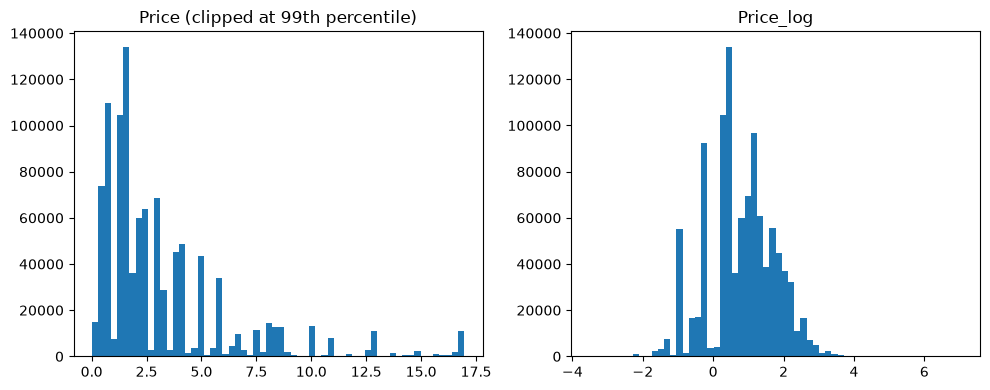

In [68]:
# Histograms
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].hist(valid["Price"].clip(upper=valid["Price"].quantile(0.99)), bins=60)
ax[0].set_title("Price (clipped at 99th percentile)")
ax[1].hist(valid["Price_log"], bins=60); ax[1].set_title("Price_log")
fig.savefig("Figures/Shapiro_Wilk.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

### Not applied techniques

| Technique | Status | Justification |
|---|---|---|
| Normalization / standardization (MinMaxScaler, StandardScaler) | Not applied | No model is fitted here. Min-max scaling of `Quantity` (range −80,995 to 80,995) would put the middle 50 % of values (1 to 10) into about 0.00006 of the 0-1 scale. Standardization is used only inside the z-score outlier flags (section 4); no scaled column is stored. |
| Imputation: `Customer ID` | Not applied | An identifier cannot be estimated. Mean or mode substitution would assign sales to a customer who may not exist. Missingness (22.24 % of clean rows) is linked to a second price level, so imputing would bias price analyses. A flag (`has_customer`) is used instead. |
| Imputation: `Description` | Not needed | All 4,382 missing values sit in zero-price rows, which the cleansing rules remove. None remain in the clean data. |
| Imputation: `Country` | Not applied | `Unspecified` is set to missing, not imputed. Mode substitution would assign `United Kingdom` to rows of unknown origin. |
| Imputation: extreme `Quantity` / `Price` | Not applied | Replacing extreme values with a default or estimate is only justified for values confirmed as errors. The extremes here could not be verified as errors (the -80,995 and -74,215 values are matched order/cancellation pairs), so they are flagged, not replaced. |
| Binning (`pd.cut`) | Not applied | The histograms and boxplots do binning to understand a distribution. Nothing in this dataset needs categorical bins. |
| Normality test (Shapiro-Wilk) | Applied | On 5 random samples of 5,000 rows (SciPy's p-value is only reliable up to N = 5,000): median W 0.35 for `Price` vs 0.99 for `Price_log`; skewness 27.71 vs 0.01. Normality is rejected for both (p < 0.005), so the log transform does not produce exactly normal data but removes almost all of the skew. |
| Pivot | Applied | Net revenue by country × month with `pivot_table`, kept as a separate table. `clean` stays in long format, one line item per row. |
| Union | Not applied | The data come as one file covering 2009-2011, so there is no second dataset to append. |
| Join | Applied | Outer join of the gross-sales table (`total_revenue`, `n_invoices`; 5,852 customers) with `net_revenue` (5,875 customers) on `Customer ID`. The 23 customers with only cancellations have no gross sales, so their `total_revenue` and `n_invoices` stay missing. The result (`cust`, one row per customer) is not merged back into `clean`, which stays one line item per row. Otherwise customer totals would repeat on every line and be overcounted when summed. Join `cust` with `clean`. |

## 6. Result

In [69]:
print("Customers raw vs clean:", dt_raw["Customer ID"].nunique(), "->", clean["Customer ID"].nunique())
display(cust.describe().style.format(
        lambda v: f"{int(v):,}" if v.is_integer() else f"{v:,.2f}"
    )
)

Customers raw vs clean: 5942 -> 5875


,n_invoices,total_revenue,net_revenue,cancelled_value,lost_revenue,lost_share
count,"5,852","5,852","5,875","5,875","5,875","2,178"
mean,6.25,"2,916.71","2,784.44",77.67,65.05,90.98
std,12.75,"14,306.87","13,799.33","1,151.94","1,084.84",21.91
min,1,2.95,"-1,343.24",0,0,0
25%,1,339.58,327.80,0,0,96.42
50%,3,856.02,835.22,0,0,100
75%,7,"2,241.03","2,164.28",19.90,17.88,100
max,373,"580,987.04","578,408.64","77,183.60","77,183.60",100


In [70]:
os.makedirs("Output", exist_ok=True)
cust.to_csv("Output/customers.csv")
clean.to_csv("Output/online_retail_II_clean.csv", index=False)

### Final Visualizations

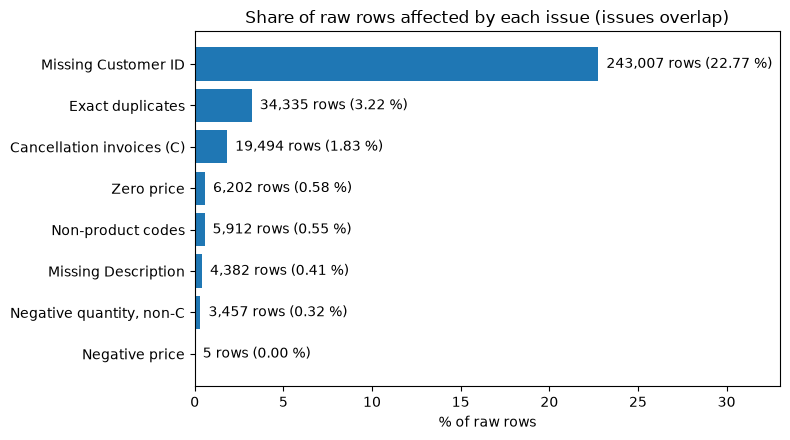

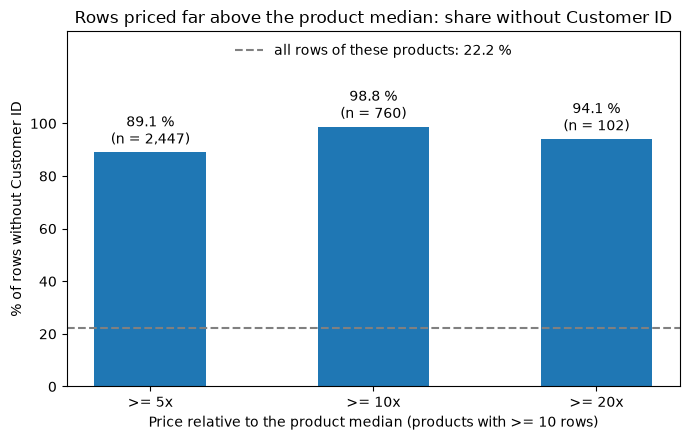

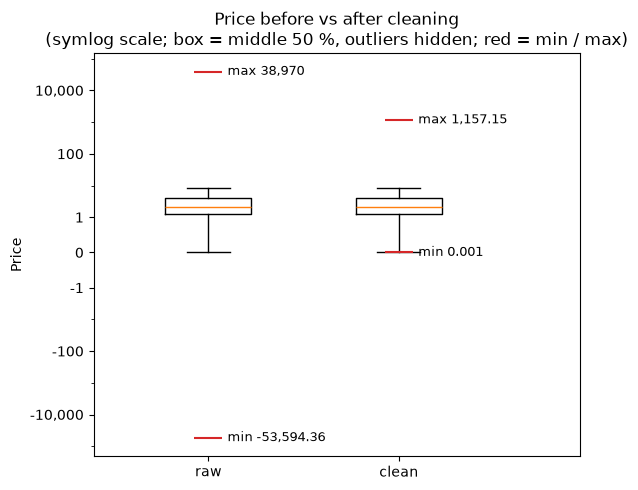

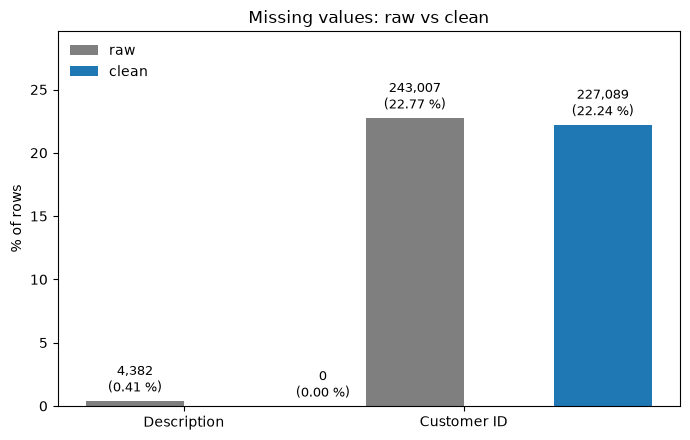

In [71]:
os.makedirs("Figures", exist_ok=True)

# 1. Data quality issues: share of raw rows affected (issues overlap)
issues = {
    "Missing Customer ID": dt["Customer ID"].isna(),
    "Cancellation invoices (C)": dt["is_cancellation"],
    "Exact duplicates": dt["is_duplicate"],
    "Non-product codes": dt["is_non_product"],
    "Zero price": dt["zero_price"],
    "Missing Description": dt["Description"].isna(),
    "Negative quantity, non-C": dt["neg_qty_noncancel"],
    "Negative price": dt["neg_price"],
}
share = pd.Series({k: v.mean() * 100 for k, v in issues.items()}).sort_values()
count = pd.Series({k: int(v.sum()) for k, v in issues.items()})

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(share.index, share.values)
for i, (k, v) in enumerate(share.items()):
    ax.text(v, i, f"  {count[k]:,} rows ({v:.2f} %)", va="center")
ax.set_xlim(0, share.max() * 1.45)
ax.set_xlabel("% of raw rows")
ax.set_title("Share of raw rows affected by each issue (issues overlap)")
fig.savefig("Figures/issue_overlap.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

# 2. Rows priced far above the product median: share without Customer ID
n_rows = clean.groupby("StockCode")["Price"].transform("size")
ratio = clean["Price"] / clean.groupby("StockCode")["Price"].transform("median")
ok = n_rows >= 10
base = (~clean.loc[ok, "has_customer"]).mean() * 100 # share without Customer ID among all rows of these products

ks = (5, 10, 20)
flagged = {k: ok & (ratio >= k) for k in ks}
share_no_id = [(~clean.loc[flagged[k], "has_customer"]).mean() * 100 for k in ks]
n_flagged = [int(flagged[k].sum()) for k in ks]

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar([f">= {k}x" for k in ks], share_no_id, width=0.5, color="tab:blue")
ax.axhline(base, color="grey", linestyle="--", label=f"all rows of these products: {base:.1f} %")
for b, v, n in zip(bars, share_no_id, n_flagged):
    ax.text(b.get_x() + b.get_width() / 2, v + 1.5, f"{v:.1f} %\n(n = {n:,})", ha="center", va="bottom")
ax.set_ylim(0, 135)
ax.set_yticks(range(0, 101, 20))
ax.set_xlabel("Price relative to the product median (products with >= 10 rows)")
ax.set_ylabel("% of rows without Customer ID")
ax.set_title("Rows priced far above the product median: share without Customer ID")
ax.legend(loc="upper center", frameon=False)
fig.savefig("Figures/extreme_price.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

# 3. Before vs after: Price and Quantity (box = middle 50 %, red = min and max)
def fmt(v):
    return f"{v:,.3f}".rstrip("0").rstrip(".")

ticks = [-1e4, -1e2, -1, 0, 1, 1e2, 1e4]
data = [dt_raw["Price"], clean["Price"]]

fig, ax = plt.subplots(figsize=(6, 5))
ax.boxplot(data, showfliers=False, widths=0.45)
for x, s in zip((1, 2), data):
    ax.scatter([x, x], [s.min(), s.max()], color="tab:red", marker="_", s=400, zorder=3)
    ax.annotate(f"max {fmt(s.max())}", (x, s.max()), xytext=(14, 0), textcoords="offset points", va="center", fontsize=9)
    ax.annotate(f"min {fmt(s.min())}", (x, s.min()), xytext=(14, 0), textcoords="offset points", va="center", fontsize=9)
ax.set_yscale("symlog", linthresh=1)
ax.set_yticks(ticks)
ax.set_yticklabels([f"{t:,.0f}" for t in ticks])
ax.set_xticks([1, 2], ["raw", "clean"])
ax.set_xlim(0.4, 2.95)
ax.set_ylabel("Price")
ax.set_title("Price before vs after cleaning\n(symlog scale; box = middle 50 %, outliers hidden; red = min / max)")
fig.savefig("Figures/comparison.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

# 4. Before vs after: missing values
fields = ["Description", "Customer ID"]
raw_n, clean_n = dt_raw[fields].isna().sum(), clean[fields].isna().sum()
raw_p, clean_p = dt_raw[fields].isna().mean() * 100, clean[fields].isna().mean() * 100

x = np.arange(len(fields))
w_rows = 0.35
fig, ax = plt.subplots(figsize=(7, 4.5))
for off, n, pct, lab, color in [(-w_rows / 2, raw_n, raw_p, "raw", "tab:grey"), (w / 2, clean_n, clean_p, "clean", "tab:blue")]:
    bars = ax.bar(x + off, pct, w_rows, label=lab, color=color)
    for b, c, v in zip(bars, n, pct):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.4, f"{c:,}\n({v:.2f} %)", ha="center", va="bottom", fontsize=9)
ax.set_xticks(x, fields)
ax.set_ylim(0, raw_p.max() * 1.3)
ax.set_ylabel("% of rows")
ax.set_title("Missing values: raw vs clean")
ax.legend(loc="upper left", frameon=False)
fig.savefig("Figures/missing_values.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

### Before / after

| | raw | clean |
|---|---|---|
| Rows | 1,067,371 | 1,021,272 (−4.32 %) |
| `Price` std | 123.55 | 4.87 |
| `Price` min / max | −53,594.36 / 38,970 | 0.001 / 1,157.15 |
| Missing `Description` | 4,382 | 0 |
| Missing `Customer ID` | 243,007 (22.77 %) | 227,089 (22.24 %) |
| `StockCode` distinct | 5,305 | 4,739 |

### Drawbacks and open points

- **Duplicate rule:** removing it from the rule set raises net revenue by about 456k.
- **Non-product rule:** for customer 15098, invoice 556444 (60 × 649.50 = 38,970) and the removed `M` row C556445 (−1 × 38,970) offset each other. Only the `M` row is removed.
- **`Customer ID`:** still missing in 22.24 % of rows and linked to a second price level. Dropping or imputing these rows would bias price analyses.
- **Thresholds:** the price-ratio rule flags 2,447 / 760 / 102 rows at 5 / 10 / 20.
- **`large_qty`:** review flag only. 9 of its rows are unpaired large orders and cannot be verified from the data.